## Model Evaluation — ROC Curves

Notebook ini menilai dua model dari notebook 05 (Logistic Regression dan CatBoost) memakai data test (6.336 peminjam, 21,5% gagal bayar), lalu mengubah skor model menjadi keputusan bisnis.

Alur notebook:
1. Kemampuan model membedakan risiko (ROC-AUC dan PR-AUC)
2. Biaya bisnis dan pemilihan threshold
3. Confusion matrix dan classification report
4. Faktor risiko utama (feature importance, koefisien, SHAP)
5. Risk tier
6. Kalibrasi skor
7. Sensitivitas terhadap asumsi biaya
8. Kesimpulan dan rekomendasi bisnis

In [1]:
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import (average_precision_score, classification_report, 
                             confusion_matrix,precision_recall_curve, 
                             roc_auc_score, roc_curve
)


pred = pd.read_parquet("../data/processed/predictions.parquet")

y_test = pred["y_true"]
lr_probs = pred["lr_prob"]
cb_probs = pred["cb_prob"]

lr_auc = roc_auc_score(y_test, lr_probs)
cb_auc = roc_auc_score(y_test, cb_probs)

print(f"LR AUC: {lr_auc:.4f}  | CatBoost AUC: {cb_auc:.4f}")

LR AUC: 0.8771  | CatBoost AUC: 0.9426


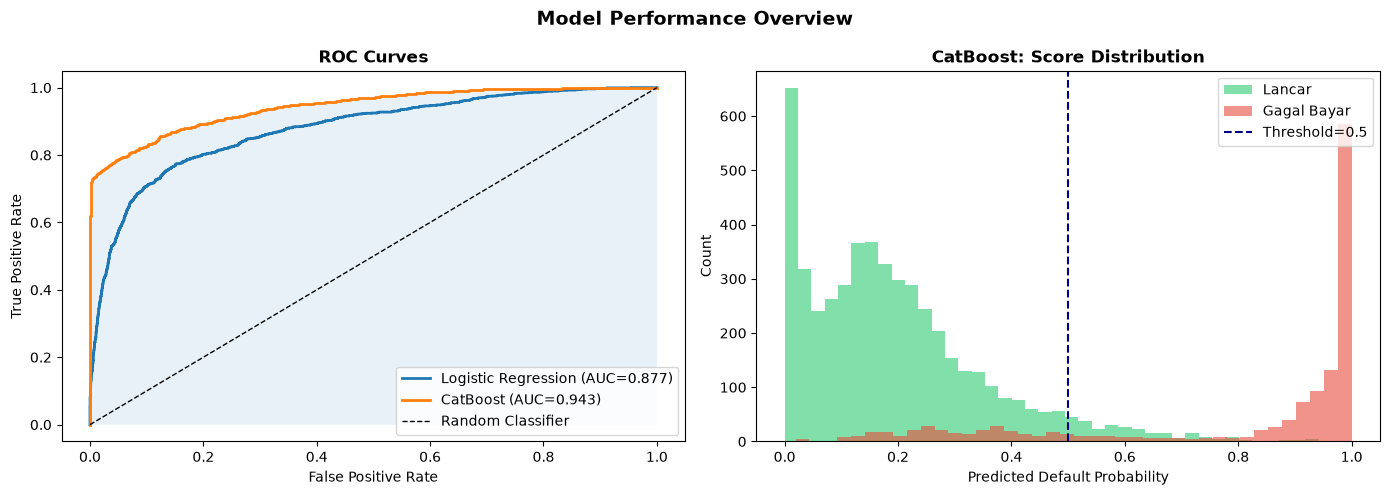

💡 CatBoost (AUC=0.943) outperforms Logistic Regression (AUC=0.877)
 The score distribution overlap shows why treshold tuning is critical


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── ROC Curves
ax = axes[0]
for name, probs, auc in [
    ("Logistic Regression", lr_probs, lr_auc),
    ("CatBoost",            cb_probs, cb_auc)
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC={auc:.3f})")
    
ax.plot([0,1], [0,1], "k--", lw=1, label="Random Classifier")
ax.fill_between(*roc_curve(y_test, cb_probs)[:2], alpha=0.1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves", fontweight="bold")
ax.legend(loc="lower right")

# ── Probability Distribution
ax = axes[1]
ax.hist(cb_probs[y_test==0], bins=40, alpha=0.6, color="#2ecc71", label="Lancar")
ax.hist(cb_probs[y_test==1], bins=40, alpha=0.6, color="#e74c3c", label="Gagal Bayar")
ax.axvline(0.5, color="navy", linestyle="--", label="Threshold=0.5")
ax.set_xlabel("Predicted Default Probability")
ax.set_ylabel("Count")
ax.set_title("CatBoost: Score Distribution", fontweight="bold")
ax.legend()

plt.suptitle("Model Performance Overview", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"💡 CatBoost (AUC={cb_auc:.3f}) outperforms Logistic Regression (AUC={lr_auc:.3f})")
print(" The score distribution overlap shows why treshold tuning is critical")

**Interpretasi**

- CatBoost (ROC-AUC 0,943) lebih unggul dari Logistic Regression (0,877), dan keduanya melewati target 0,80.
- Kurva ROC CatBoost berada di atas Logistic Regression hampir di semua titik, jadi CatBoost lebih baik di hampir semua pilihan threshold, bukan hanya rata-ratanya.
- ROC-AUC 0,943 artinya: kalau diambil satu peminjam gagal bayar dan satu peminjam lancar secara acak, sekitar 94% kemungkinannya CatBoost memberi skor risiko lebih tinggi ke peminjam yang gagal bayar.
- Di notebook 05, AUC CatBoost di data train 0,956 dan di data test 0,943. Selisihnya kecil (0,013), jadi model tidak overfitting.
- Sebaran skor: peminjam lancar menumpuk di skor rendah dan peminjam gagal bayar di skor tinggi. Area tumpang tindih di tengah adalah tempat kesalahan terjadi, sehingga pemilihan threshold menentukan hasil akhirnya.

PR-AUC LR: 0.7316  |  CatBoost; 0.8954    | baseline (acak): 0.2154


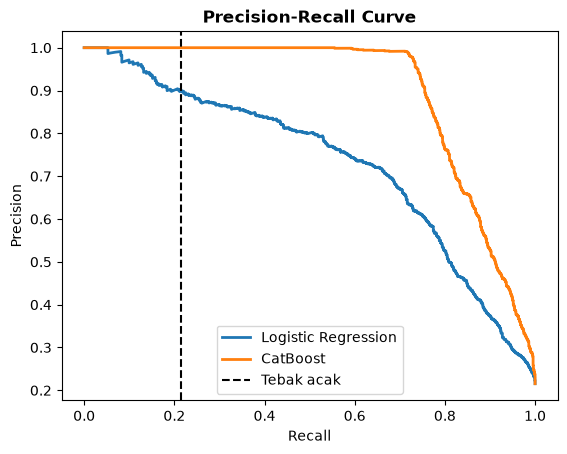

In [3]:
lr_ap = average_precision_score(y_test, lr_probs)
cb_ap = average_precision_score(y_test, cb_probs)
print(f"PR-AUC LR: {lr_ap:.4f}  |  CatBoost; {cb_ap:.4f}    | baseline (acak): {y_test.mean():.4f}")

for name, probs in [("Logistic Regression", lr_probs), ("CatBoost", cb_probs)]:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    plt.plot(rec, prec, lw=2, label=name)
plt.axvline(y_test.mean(), color="k", ls="--", label="Tebak acak")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve", fontweight="bold")
plt.legend()
plt.show()

**Interpretasi**

- PR-AUC mengukur seberapa baik model menemukan peminjam gagal bayar tanpa terlalu banyak salah tandai. Ukuran ini lebih peka untuk data tidak seimbang dibanding ROC-AUC.
- Model acak hanya mendapat PR-AUC 0,215 (sama dengan proporsi gagal bayar). Logistic Regression mendapat 0,732 dan CatBoost 0,895.
- Selisih kedua model lebih terlihat di PR-AUC (0,16) dibanding ROC-AUC (0,07). Artinya keunggulan CatBoost paling terasa justru pada kelas yang penting bagi bisnis, yaitu peminjam gagal bayar.

## Business Cost of Errors

In credit risk, the two types of errors have very different business costs:

| Error Type | Meaning | Business Impact |
|---|---|---|
| False Negative (FN) | We approved a loan that defaulted | 🔴 HIGH COST: we lose the loan amount |
| False Positive (FP) | We rejected a good borrower | 🟡 LOWER COST: we lose potential interest profit |

**Our cost assumptions:**

- FN cost = $500 per missed default (partial loss estimate)
- FP cost = $50 per wrongly rejected customer (lost profit opportunity)

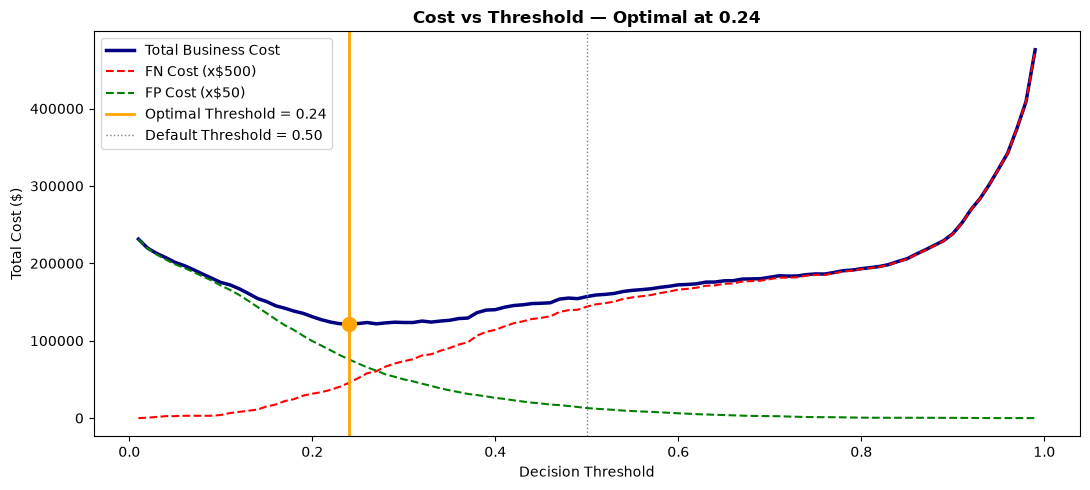

📍 Default threshold (0.50) total cost: $157,000
📍 Optimal threshold (0.24) total cost: $121,300
💵 Cost savings from threshold tuning:  $35,700

💡 By lowering the threshold, we catch more defaults (fewer FNs)
at the expense of rejecting more good borrowers (more FPs).
Since FN costs 10× more than FP, we shift the threshold lower


In [4]:
# Define Business Costs
COST_FN = 500 # Missing a default (most expensive)
COST_FP = 50 # Wrongly rejecting a good borrower

# ── Sweep thresholds from 0.01 to 0.99
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
total_costs, fn_costs, fp_costs = [], [], []

for thres in thresholds:
    preds = (cb_probs >= thres).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    total = fp * COST_FP + fn * COST_FN
    total_costs.append(total)
    fn_costs.append(fn * COST_FN)
    fp_costs.append(fp * COST_FP)
    
# ── Find optimal threshold
optimal_idx = np.argmin(total_costs)
optimal_thresh = thresholds[optimal_idx]
optimal_cost = total_costs[optimal_idx]

# ── Plot cost curves
plt.figure(figsize=(11, 5))
plt.plot(thresholds, total_costs, "navy", lw=2.5, label="Total Business Cost")
plt.plot(thresholds, fn_costs, "red", lw=1.5, linestyle="--", label=f"FN Cost (x${COST_FN})")
plt.plot(thresholds, fp_costs, "green", lw=1.5, linestyle="--", label=f"FP Cost (x${COST_FP})")
plt.axvline(optimal_thresh, color="orange", linewidth=2, label=f"Optimal Threshold = {optimal_thresh:.2f}")
plt.axvline(0.5, color="grey", linewidth=1, linestyle=":", label="Default Threshold = 0.50")
plt.scatter([optimal_thresh], [optimal_cost], color="orange", zorder=5, s=100)
plt.xlabel("Decision Threshold")
plt.ylabel("Total Cost ($)")
plt.title(f"Cost vs Threshold — Optimal at {optimal_thresh:.2f}", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

# Compare costs at 0.5 vs optimal
tn, fp, fn, tp = confusion_matrix(y_test, (cb_probs >= 0.5).astype(int)).ravel()
default_cost = fp * COST_FP + fn * COST_FN

savings = default_cost - optimal_cost
print(f"📍 Default threshold (0.50) total cost: ${default_cost:,.0f}")
print(f"📍 Optimal threshold ({optimal_thresh:.2f}) total cost: ${optimal_cost:,.0f}")
print(f"💵 Cost savings from threshold tuning:  ${savings:,.0f}")
print("\n💡 By lowering the threshold, we catch more defaults (fewer FNs)")
print("at the expense of rejecting more good borrowers (more FPs).")
print("Since FN costs 10× more than FP, we shift the threshold lower")


**Interpretasi**

- Kurva merah (biaya FN) turun ketika threshold diturunkan karena lebih banyak gagal bayar tertangkap. Kurva hijau (biaya FP) naik karena lebih banyak peminjam baik ikut ditandai.
- Total biaya terendah ada di threshold **0,24**, jauh di bawah 0,50, karena satu gagal bayar yang lolos (FN) 10 kali lebih mahal dari satu penolakan yang keliru (FP).
- Total biaya turun dari **$157.000** (threshold 0,50) menjadi **$121.300** (threshold 0,24), hemat sekitar **$35.700 (23%)**.
- Kurva total biaya cukup datar di sekitar titik optimal, jadi threshold di kisaran tersebut menghasilkan biaya yang hampir sama. Ini memberi ruang bagi bisnis untuk menyesuaikan threshold dengan kapasitas tim verifikasi.

Catatan: threshold optimal dipilih dan dilaporkan di data test yang sama, sehingga penghematan biaya kemungkinan sedikit lebih optimis dari kenyataan. Idealnya threshold dipilih di data validasi terpisah.

## Final Model Evaluation at Optimal Threshold

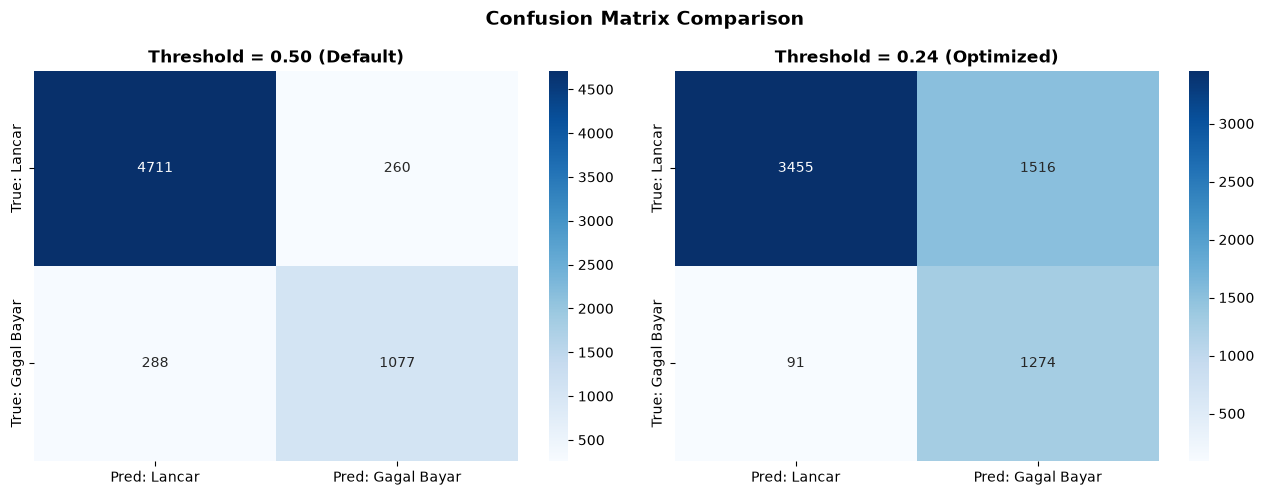


--- Classification Report at DEFAULT (Gagal Bayar) threshold (0.50) ---
              precision    recall  f1-score   support

      Lancar       0.94      0.95      0.95      4971
 Gagal Bayar       0.81      0.79      0.80      1365

    accuracy                           0.91      6336
   macro avg       0.87      0.87      0.87      6336
weighted avg       0.91      0.91      0.91      6336

--- Classification Report at OPTIMAL threshold (0.24) ---
              precision    recall  f1-score   support

      Lancar       0.97      0.70      0.81      4971
 Gagal Bayar       0.46      0.93      0.61      1365

    accuracy                           0.75      6336
   macro avg       0.72      0.81      0.71      6336
weighted avg       0.86      0.75      0.77      6336

💡 At the optimal threshold:
• Recall for Default (Gagal Bayar) class improves — we catch more actual defaults
• Precision for Default (Gagal Bayar) class may drop — more false alarms on good borrowers
• But the TOTA

In [5]:
# Predicitons at both thresholds
preds_default = (cb_probs >= 0.50).astype(int)
preds_optimal = (cb_probs >= optimal_thresh).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, preds, title in [
    (axes[0], preds_default, "Threshold = 0.50 (Default)"),
    (axes[1], preds_optimal, f"Threshold = {optimal_thresh:.2f} (Optimized)")
]:
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax = ax,
                xticklabels=["Pred: Lancar", "Pred: Gagal Bayar"], yticklabels=["True: Lancar", "True: Gagal Bayar"])
    ax.set_title(title, fontweight="bold")
    
plt.suptitle("Confusion Matrix Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\n--- Classification Report at DEFAULT (Gagal Bayar) threshold (0.50) ---")
print(classification_report(y_test, preds_default, target_names=["Lancar", "Gagal Bayar"]))

print(f"--- Classification Report at OPTIMAL threshold ({optimal_thresh:.2f}) ---")
print(classification_report(y_test, preds_optimal, target_names=["Lancar","Gagal Bayar"]))

print("💡 At the optimal threshold:")
print("• Recall for Default (Gagal Bayar) class improves — we catch more actual defaults")
print("• Precision for Default (Gagal Bayar) class may drop — more false alarms on good borrowers")
print("• But the TOTAL BUSINESS COST is lower — that is what matters")

In [6]:
# Simpan aturan keputusan untuk aplikasi scoring (mengikuti hasil notebook ini)
y_train = pd.read_parquet("../data/processed/y_train.parquet")["loan_status"]
W = float((y_train == 0).sum() / (y_train == 1).sum())

scoring_config = {
    "threshold": float(optimal_thresh),
    "tier_bins": [0, float(optimal_thresh), 0.50, 0.80, 1.0],
    "tier_labels": ["Low Risk", "Medium Risk", "High Risk", "Very High Risk"],
    "class_weight_W": W,
    "cost_fn": COST_FN,
    "cost_fp": COST_FP,
}
joblib.dump(scoring_config, "../models/scoring_config.pkl")
print(scoring_config)

{'threshold': 0.24, 'tier_bins': [0, 0.24, 0.5, 0.8, 1.0], 'tier_labels': ['Low Risk', 'Medium Risk', 'High Risk', 'Very High Risk'], 'class_weight_W': 3.641208791208791, 'cost_fn': 500, 'cost_fp': 50}


**Interpretasi**

| | Threshold 0,50 | Threshold 0,24 |
|---|---|---|
| Recall gagal bayar (gagal bayar yang tertangkap) | 79% | 93% |
| Gagal bayar yang lolos disetujui | 21% | 7% |
| Precision gagal bayar (yang ditandai dan memang gagal bayar) | 81% | 46% |
| Peminjam lancar yang ikut ditandai berisiko | 5% | 30% |
| Accuracy | 0,91 | 0,75 |

- Di threshold 0,24, gagal bayar yang lolos turun dari sekitar 1 dari 5 menjadi sekitar 1 dari 14.
- Konsekuensinya, sekitar 30% peminjam lancar ikut ditandai berisiko. Mereka sebaiknya **ditinjau ulang**, bukan langsung ditolak, supaya tidak kehilangan nasabah baik.
- Accuracy turun dari 0,91 ke 0,75, dan itu disengaja. Tujuan threshold ini meminimalkan biaya, bukan memaksimalkan accuracy. Pada data tidak seimbang, accuracy bukan ukuran yang tepat untuk keputusan kredit.

## Feature Importance Analysis

In [7]:
from catboost import CatBoostClassifier

cb_model = CatBoostClassifier()
cb_model.load_model("../models/cb_model.cbm")

lr_model = joblib.load("../models/lr_model.pkl")

X_train = pd.read_parquet("../data/processed/X_train.parquet")

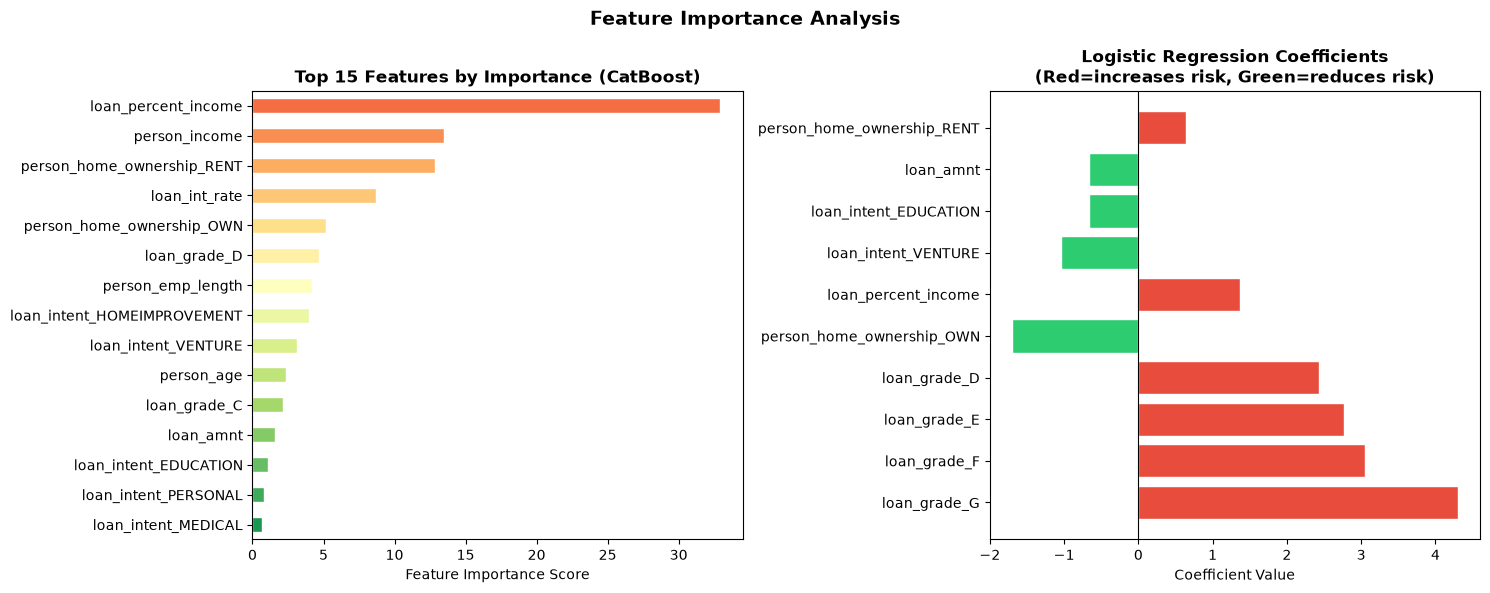

💡 Key Risk Drivers:
Top 3 by CatBoost:
Importance per fitur asal (one-hot dijumlahkan):
loan_percent_income           32.88
person_home_ownership         18.04
person_income                 13.48
loan_intent                    9.68
loan_int_rate                  8.73
loan_grade                     8.27
person_emp_length              4.17
person_age                     2.35
loan_amnt                      1.61
cb_person_cred_hist_length     0.41
cb_person_default_on_file      0.39

Top 3: ['loan_percent_income', 'person_home_ownership', 'person_income']


In [8]:
# CatBoost Feature Importance
importance = pd.Series(
    cb_model.get_feature_importance(),
    index = X_train.columns
).sort_values(ascending=True)

# Show top 15 features
top15 = importance.tail(15)

fig, axes = plt.subplots(1, 2, figsize=(15,6))

# ── Horizontal bar chart
colors = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(top15)))
top15.plot(kind="barh", ax=axes[0], color=colors[::-1], edgecolor="white")
axes[0].set_title("Top 15 Features by Importance (CatBoost)", fontweight="bold")
axes[0].set_xlabel("Feature Importance Score")

# ── Logistic Regression coefficients
lr_coef = pd.Series(lr_model.coef_[0], index=X_train.columns)
top_lr = lr_coef.abs().sort_values(ascending=False).head(10)
colors2 = ["#e74c3c" if lr_coef[f] > 0 else "#2ecc71" for f in top_lr.index]

axes[1].barh(top_lr.index, lr_coef[top_lr.index], color=colors2, edgecolor="white")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Logistic Regression Coefficients\n(Red=increases risk, Green=reduces risk)", fontweight="bold")
axes[1].set_xlabel("Coefficient Value")

plt.suptitle("Feature Importance Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("💡 Key Risk Drivers:")
print(f"Top 3 by CatBoost:")

def base_feature(col):
    for p in ["person_home_ownership", "loan_intent", "loan_grade"]:
        if col.startswith(p + "_"):
            return p
    return col

importance_grouped = importance.groupby(base_feature).sum().sort_values(ascending=False)
print(f"Importance per fitur asal (one-hot dijumlahkan):")
print(importance_grouped.round(2).to_string())
print("\nTop 3:", importance_grouped.head(3).index.tolist())

**Interpretasi feature importance**

Importance CatBoost dijumlahkan per fitur asal (kolom one-hot digabung), supaya fitur kategori tidak terlihat kecil karena tersebar di banyak kolom.

1. **loan_percent_income (32,9)** adalah faktor paling dominan: porsi pinjaman dibanding pendapatan.
2. **person_home_ownership (18,0)**: status tempat tinggal, terutama penyewa (RENT) dan pemilik rumah (OWN).
3. **person_income (13,5)**: besar pendapatan.
4. **loan_intent (9,7), loan_int_rate (8,7), loan_grade (8,3)** berada di level menengah.
5. **cb_person_default_on_file (0,4)** hampir tidak dipakai CatBoost. Kemungkinan informasinya sudah terwakili oleh grade dan suku bunga.

Pada Logistic Regression, koefisien terbesar adalah loan_grade E sampai G (dibandingkan grade A). Kedua model berbeda urutan karena cara membagi informasi berbeda: CatBoost bisa memakai kombinasi bunga, pendapatan, dan rasio pinjaman, sedangkan Logistic Regression lebih bergantung pada grade. Keduanya sepakat bahwa beban pinjaman dan status tempat tinggal penting.

Catatan: koefisien loan_amnt negatif bukan berarti pinjaman besar lebih aman. loan_amnt, person_income, dan loan_percent_income saling berkaitan, sehingga pengaruhnya terbagi.

In [9]:
from catboost import Pool

X_test = pd.read_parquet("../data/processed/X_test.parquet")
shap_vals = cb_model.get_feature_importance(Pool(X_test), type="ShapValues")[:, :-1]
shap_df = pd.DataFrame(shap_vals, columns=X_test.columns)

summary = pd.DataFrame({
    "mean_abs_shap": shap_df.abs().mean(),
    "arah" : [np.corrcoef(X_test[c].astype(float), shap_df[c])[0, 1] for c in X_test.columns]
}).sort_values("mean_abs_shap", ascending=False)
summary["pengaruh"] = np.where(summary["arah"] > 0, "naik = lebih berisiko", "naik = lebih aman")
summary.head(10).round(3)

,mean_abs_shap,arah,pengaruh
loan_percent_income,1.109,0.738,naik = lebih berisiko
person_income,0.642,-0.491,naik = lebih aman
person_home_ownership_RENT,0.601,0.837,naik = lebih berisiko
loan_int_rate,0.553,0.956,naik = lebih berisiko
loan_intent_VENTURE,0.435,-0.967,naik = lebih aman
loan_grade_D,0.355,0.924,naik = lebih berisiko
person_home_ownership_OWN,0.329,-0.992,naik = lebih aman
loan_intent_EDUCATION,0.133,-0.824,naik = lebih aman
person_emp_length,0.132,-0.359,naik = lebih aman
loan_intent_HOMEIMPROVEMENT,0.127,0.709,naik = lebih berisiko


**Interpretasi SHAP (arah pengaruh)**

Feature importance hanya menunjukkan seberapa besar pengaruh, SHAP menunjukkan arahnya:

- Menaikkan risiko: **porsi pinjaman terhadap pendapatan tinggi**, **suku bunga tinggi**, **status menyewa (RENT)**, **grade D**, dan tujuan pinjaman renovasi rumah (HOMEIMPROVEMENT).
- Menurunkan risiko: **pendapatan tinggi**, **memiliki rumah sendiri (OWN)**, **lama bekerja lebih panjang**, serta tujuan pinjaman usaha (VENTURE) dan pendidikan (EDUCATION).

Arah ini masuk akal secara bisnis: peminjam dengan beban cicilan berat dibanding pendapatannya dan tanpa aset rumah sendiri lebih rentan gagal bayar.

Catatan: ini hubungan statistik dalam data, bukan bukti sebab-akibat. Misalnya grade D tidak menyebabkan gagal bayar, tetapi grade D diberikan kepada peminjam yang sudah dinilai berisiko.

## Risk Scoring — Assign Risk Tiers

In [10]:
raw = pd.read_parquet("../data/processed/credit_risk_dataset_clean.parquet")  # versi asli
pred = pd.read_parquet("../data/processed/predictions.parquet")

# ambil baris asli yang sama dengan data test (pakai index)
results = raw.loc[X_test.index].copy()
results["cb_prob"] = cb_model.predict_proba(X_test)[:, 1]

--- Risk Tier Summary ---
                count  actual_default_rate  avg_pred_prob
risk_tier                                                
Low Risk         3546                  2.6           11.2
Medium Risk      1453                 13.6           33.7
High Risk         346                 28.0           61.3
Very High Risk    991                 98.9           96.4


C:\Users\APTIKA\AppData\Local\Temp\ipykernel_20544\3418588897.py:37: UserWarning: Glyph 128450 (\N{CARD INDEX DIVIDERS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\APTIKA 2025\RIMA\credit-risk-predicition\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128450 (\N{CARD INDEX DIVIDERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


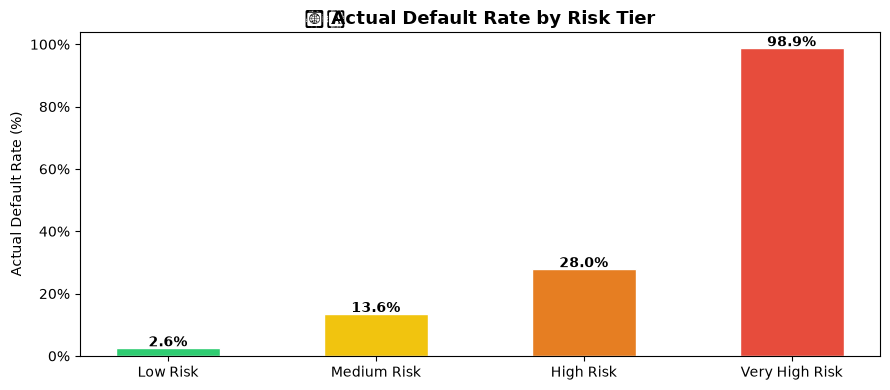


Tingkat gagal bayar aktual naik konsisten dari Low ke Very High Risk,
jadi model mengurutkan risiko dengan baik. Namun avg_pred_prob lebih tinggi
dari tingkat aktual karena bobot kelas, jadi skor belum terkalibrasi.


In [11]:
# Assign risk buckets based on predicted probability
results["true_label"] = results["loan_status"]
results["default_prob"] = results["cb_prob"]

def assign_risk(prob):
    if prob < optimal_thresh:   return "Low Risk"
    elif prob < 0.50:           return "Medium Risk"
    elif prob < 0.80:           return "High Risk"
    else:                       return "Very High Risk"
    
results["risk_tier"] = results["default_prob"].apply(assign_risk)

# Actual default rate within each tier
tier_stats = results.groupby("risk_tier").agg(count=("true_label", "count"), 
                                              actual_default_rate=("true_label", "mean"),
                                              avg_pred_prob=("default_prob", "mean")).reindex(["Low Risk", "Medium Risk", "High Risk", "Very High Risk"])

tier_stats["actual_default_rate"] = (tier_stats["actual_default_rate"] * 100).round(1)
tier_stats["avg_pred_prob"] = (tier_stats["avg_pred_prob"] * 100).round(1)

print("--- Risk Tier Summary ---")
print(tier_stats.to_string())

# Visualize
fig, ax = plt.subplots(figsize=(9, 4))
colors3 = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c']
bars = ax.bar(tier_stats.index, tier_stats['actual_default_rate'],
              color=colors3, edgecolor='white', width=0.5)

for bar, val in zip(bars, tier_stats['actual_default_rate']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', fontweight='bold')

ax.set_title('🗂️ Actual Default Rate by Risk Tier', fontweight='bold', fontsize=13)
ax.set_ylabel('Actual Default Rate (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.show()

print("\nTingkat gagal bayar aktual naik konsisten dari Low ke Very High Risk,")
print("jadi model mengurutkan risiko dengan baik. Namun avg_pred_prob lebih tinggi")
print("dari tingkat aktual karena bobot kelas, jadi skor belum terkalibrasi.")


**Interpretasi**

| Tier | Porsi peminjam | Gagal bayar aktual |
|---|---|---|
| Low Risk (skor < 0,24) | 56% | 2,6% |
| Medium Risk (0,24 – 0,50) | 23% | 13,6% |
| High Risk (0,50 – 0,80) | 5% | 28,0% |
| Very High Risk (≥ 0,80) | 16% | 98,9% |

- Tingkat gagal bayar aktual naik konsisten dari 2,6% ke 98,9%, jadi model **mengurutkan risiko dengan sangat baik**.
- Tier Very High Risk hanya 16% dari peminjam, tetapi memuat sekitar **72% dari seluruh kasus gagal bayar**.
- Lebih dari separuh peminjam (56%) masuk Low Risk dengan tingkat gagal bayar hanya 2,6%, sehingga bisa diproses cepat.
- Rata-rata skor prediksi lebih tinggi dari kenyataan di tier Low sampai High (misalnya 33,7% vs 13,6% di Medium). Ini akibat bobot kelas saat training, jadi skor asli adalah **peringkat risiko**, bukan peluang. Bagian berikutnya membahas kalibrasinya.

## Kalibrasi Skor

Model dilatih dengan bobot kelas (gagal bayar dihitung sekitar 3,64 kali lebih penting), sehingga skornya cenderung lebih tinggi dari peluang sebenarnya. Skor dikoreksi dengan rumus `p / (p + W × (1 − p))` dengan W = 3,64 untuk membatalkan pengaruh bobot tersebut.

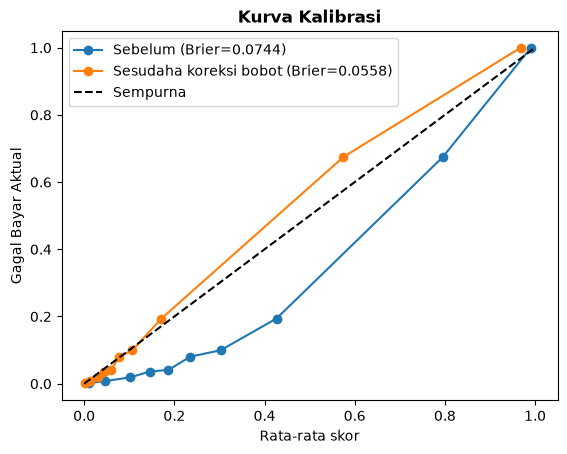

In [12]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

W = 3.64
cb_cal = cb_probs / (cb_probs + W * (1 - cb_probs))

for name, p in [("Sebelum", cb_probs), ("Sesudaha koreksi bobot", cb_cal)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac, marker="o", label=f"{name} (Brier={brier_score_loss(y_test, p):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Sempurna")
plt.xlabel("Rata-rata skor");
plt.ylabel("Gagal Bayar Aktual")
plt.title("Kurva Kalibrasi", fontweight="bold")
plt.legend()
plt.show()

**Interpretasi**

- Sebelum koreksi, kurva berada di bawah garis diagonal: skor model lebih tinggi dari tingkat gagal bayar sebenarnya.
- Setelah koreksi, kurva jauh lebih dekat ke diagonal, dan Brier score turun dari **0,0744** menjadi **0,0558** (sekitar 25% lebih baik). Brier score adalah rata-rata kesalahan kuadrat antara skor dan kenyataan, makin kecil makin baik.
- Di skor menengah, hasil koreksi sedikit di atas diagonal, artinya sedikit lebih rendah dari kenyataan. Kalau dibutuhkan angka peluang yang lebih presisi, bisa dicoba isotonic regression di data validasi terpisah.
- Kalibrasi tidak mengubah urutan peminjam, sehingga ROC-AUC dan keputusan di threshold 0,24 tetap sama. Threshold 0,24 pada skor asli setara dengan sekitar 0,08 pada skor terkoreksi.
- Penggunaan: skor asli untuk keputusan dan tier, skor terkoreksi kalau perlu menyampaikan perkiraan peluang gagal bayar.

## Sensitivitas terhadap Asumsi Biaya

Biaya FN $500 hanya asumsi. Tabel berikut menguji bagaimana threshold optimal berubah kalau biaya gagal bayar yang lolos berbeda (biaya FP tetap $50).

In [13]:
rows = []
for fn_costs in [200, 500, 1000, 2000]:
    costs = []
    for t in thresholds:
        tn, fp, fn, tp = confusion_matrix(y_test, (cb_probs >= t).astype(int)).ravel()
        costs.append(fn * fn_costs + fp * COST_FP)
    rows.append({"biaya FN": fn_costs, "threshold optimal": thresholds[int(np.argmin(costs))]})
pd.DataFrame(rows)

,biaya FN,threshold optimal
0,200,0.46
1,500,0.24
2,1000,0.22
3,2000,0.10


**Interpretasi**

- Makin mahal biaya gagal bayar yang lolos, makin rendah threshold optimal: 0,46 (FN $200), 0,24 (FN $500), 0,22 (FN $1.000), dan 0,10 (FN $2.000).
- Threshold relatif stabil di kisaran 0,22 sampai 0,24 untuk biaya FN $500 sampai $1.000, sehingga rekomendasi threshold 0,24 cukup tahan terhadap perubahan asumsi di rentang tersebut.
- Kalau biaya kerugian sebenarnya jauh lebih kecil (sekitar $200), threshold mendekati 0,50. Kalau jauh lebih besar (sekitar $2.000), threshold perlu sangat rendah dan jumlah peminjam yang perlu ditinjau akan naik tajam.
- Karena itu, angka biaya sebaiknya dikonfirmasi dengan data kerugian riil sebelum threshold dipakai di produksi.

## Kesimpulan

1. **CatBoost dipilih sebagai model utama.** ROC-AUC 0,943 dan PR-AUC 0,895, lebih unggul dari Logistic Regression (0,877 dan 0,732), dengan selisih AUC train-test hanya 0,013.
2. **Threshold 0,24 lebih menguntungkan dari 0,50.** Gagal bayar yang tertangkap naik dari 79% ke 93%, dan total biaya kesalahan turun sekitar 23% (dari $157.000 ke $121.300) dengan asumsi biaya FN $500 dan FP $50.
3. **Faktor risiko utama** adalah porsi pinjaman terhadap pendapatan, status tempat tinggal, pendapatan, suku bunga, dan grade pinjaman.
4. **Risk tier mengurutkan risiko dengan konsisten**, dari 2,6% gagal bayar di Low Risk hingga 98,9% di Very High Risk.
5. **Skor asli adalah peringkat risiko.** Setelah koreksi bobot kelas, skor lebih dekat dengan peluang sebenarnya (Brier score 0,0744 menjadi 0,0558).

## Rekomendasi Bisnis

**1. Terapkan alur persetujuan berdasarkan risk tier**

| Tier | Porsi pengajuan | Tindakan yang disarankan |
|---|---|---|
| Low Risk (skor < 0,24) | 56% | Proses otomatis / jalur cepat |
| Medium Risk (0,24 – 0,50) | 23% | Verifikasi standar: slip gaji, status pekerjaan, rekening |
| High Risk (0,50 – 0,80) | 5% | Verifikasi ketat, tawarkan plafon lebih kecil atau tenor berbeda |
| Very High Risk (≥ 0,80) | 16% | Tolak, atau setujui hanya dengan jaminan / penjamin |

Dengan alur ini, lebih dari separuh pengajuan bisa diproses cepat, sementara tim analis fokus pada 44% pengajuan yang lebih berisiko.

**2. Jadikan rasio pinjaman terhadap pendapatan sebagai aturan utama**

Faktor ini paling berpengaruh di kedua model. Bisnis bisa menetapkan batas maksimal rasio pinjaman terhadap pendapatan, atau menyesuaikan plafon pinjaman otomatis berdasarkan pendapatan peminjam.

**3. Beri perhatian khusus pada peminjam yang menyewa tempat tinggal**

Status RENT menaikkan risiko, sedangkan pemilik rumah sendiri lebih aman. Untuk penyewa dengan rasio pinjaman tinggi, pertimbangkan verifikasi tambahan atau plafon yang lebih konservatif.

**4. Kaji ulang kebijakan grade dan suku bunga**

Grade D sampai G dan suku bunga tinggi berhubungan kuat dengan gagal bayar. Bunga tinggi memang mencerminkan risiko, tetapi juga menambah beban cicilan. Perlu dikaji apakah peminjam grade rendah lebih baik ditawari plafon kecil daripada bunga yang sangat tinggi.

**5. Tetapkan threshold bersama tim bisnis**

Threshold 0,24 berdasarkan asumsi biaya. Gunakan tabel sensitivitas untuk memilih threshold sesuai data kerugian riil dan kapasitas tim verifikasi. Di threshold 0,24, sekitar 30% peminjam lancar ikut ditinjau, sehingga kapasitas tim perlu diperhitungkan.

**6. Pantau model secara berkala**

Pantau tingkat gagal bayar aktual per tier setiap bulan. Kalau tingkat gagal bayar di tier Low Risk mulai naik atau sebaran skor berubah, model perlu dilatih ulang dengan data terbaru.

## Batasan dan Langkah Selanjutnya

**Batasan**
- Biaya FN $500 dan FP $50 adalah asumsi, bukan data kerugian riil.
- Threshold optimal dipilih dan dilaporkan di data test yang sama, sehingga penghematan biaya kemungkinan sedikit lebih optimis dari kenyataan.
- Feature importance dan SHAP menunjukkan hubungan statistik, bukan sebab-akibat.
- Data bersifat historis. Pola peminjam dan kondisi ekonomi bisa berubah.

**Langkah selanjutnya**
1. Memilih threshold di data validasi terpisah, lalu melaporkan hasil di data test.
2. Mengkonfirmasi angka biaya dengan data kerugian riil.
3. Membangun aplikasi scoring (Streamlit / FastAPI) yang memakai model, aturan preprocessing, threshold 0,24, dan batas tier yang sama.